In [1]:
import itertools
from math import comb

import numpy as np
import qutip as qt

# Finalized Code

In [2]:
import itertools
from math import comb


def all_codewords(N, b, K_min=2):
    """
    Every valid codeword |v_S> = (|S> + |S^c>)/sqrt(2) of the imbalance code in sector b.

    Valid means:
        - each mirror pair p = (p, N-1-p) is empty or active (one excitation); no doubles
        - b even, so M = 0 puts b/2 excitations on each half
        - K = b/2 >= K_min, so dim C = C(2K, K)/2 >= 3
        - b <= N/2, at most one excitation per pair
        - S and S^c are the same codeword; keep the label containing the first active pair

    Yields:
        t     : pair assignment, tuple of 0/1 of length N/2
        S     : frozenset of active pairs whose excitation is on the LEFT site
        occS  : sorted occupied sites of |S>
        occSc : sorted occupied sites of |S^c> (the mirror image)
    """
    m = N // 2
    if N % 2 or b % 2 or b < 2 * K_min or b > m:
        return
    K = b // 2

    for A in itertools.combinations(range(m), b):          # active pairs; all others empty
        t = tuple(1 if p in A else 0 for p in range(m))
        for S in itertools.combinations(A, K):
            if A[0] not in S:                               # drop the S^c duplicate
                continue
            S = frozenset(S)
            occS  = sorted(p if p in S else N - 1 - p for p in A)
            occSc = sorted(N - 1 - p if p in S else p for p in A)
            yield t, S, occS, occSc


# ---------------- check ----------------
N, b = 10, 4
cw = list(all_codewords(N, b))
K = b // 2
print(len(cw), "=", comb(N // 2, b) * comb(2 * K, K) // 2)  # assignments x dim C
for t, S, occS, occSc in cw[:]:
    print("t=","".join(map(str, t)), ";S (left occ pairs)=",sorted(S), ";occS=",occS,";occSc=", occSc)

15 = 15
t= 11110 ;S (left occ pairs)= [0, 1] ;occS= [0, 1, 6, 7] ;occSc= [2, 3, 8, 9]
t= 11110 ;S (left occ pairs)= [0, 2] ;occS= [0, 2, 6, 8] ;occSc= [1, 3, 7, 9]
t= 11110 ;S (left occ pairs)= [0, 3] ;occS= [0, 3, 7, 8] ;occSc= [1, 2, 6, 9]
t= 11101 ;S (left occ pairs)= [0, 1] ;occS= [0, 1, 5, 7] ;occSc= [2, 4, 8, 9]
t= 11101 ;S (left occ pairs)= [0, 2] ;occS= [0, 2, 5, 8] ;occSc= [1, 4, 7, 9]
t= 11101 ;S (left occ pairs)= [0, 4] ;occS= [0, 4, 7, 8] ;occSc= [1, 2, 5, 9]
t= 11011 ;S (left occ pairs)= [0, 1] ;occS= [0, 1, 5, 6] ;occSc= [3, 4, 8, 9]
t= 11011 ;S (left occ pairs)= [0, 3] ;occS= [0, 3, 5, 8] ;occSc= [1, 4, 6, 9]
t= 11011 ;S (left occ pairs)= [0, 4] ;occS= [0, 4, 6, 8] ;occSc= [1, 3, 5, 9]
t= 10111 ;S (left occ pairs)= [0, 2] ;occS= [0, 2, 5, 6] ;occSc= [3, 4, 7, 9]
t= 10111 ;S (left occ pairs)= [0, 3] ;occS= [0, 3, 5, 7] ;occSc= [2, 4, 6, 9]
t= 10111 ;S (left occ pairs)= [0, 4] ;occS= [0, 4, 6, 7] ;occSc= [2, 3, 5, 9]
t= 01111 ;S (left occ pairs)= [1, 2] ;occS= [1, 2, 5, 6]

In [4]:
def get_V_W(N, alpha, Jz):
    """V(i) = -2 Jz sum_{j!=i} |i-j|^-alpha,  W(i,j) = 4 Jz |i-j|^-alpha (W[i,i] = 0)."""
    r = np.abs(np.subtract.outer(np.arange(N), np.arange(N))).astype(float)
    np.fill_diagonal(r, np.inf)
    W = 4.0 * Jz * r ** (-alpha)
    V = -0.5 * W.sum(axis=1)
    return V, W


def build_Heff_sector(N, b, alpha, Jz, Jx):
    """
    Dense H_eff^b = T + U in the configuration basis of sector b, dimension C(N, b).

    Returns:
        H     : (D, D) real symmetric matrix
        index : dict, sorted tuple of occupied sites -> row of H
    """
    V, W = get_V_W(N, alpha, Jz)
    basis = list(itertools.combinations(range(N), b))
    index = {c: k for k, c in enumerate(basis)}
    H = np.zeros((len(basis), len(basis)))
    for k, c in enumerate(basis):
        occ = np.asarray(c)
        H[k, k] = V[occ].sum() + 0.5 * W[np.ix_(occ, occ)].sum()   # E(c), Eq. (1)
        occ_set = set(c)
        for i in c:                                    # each bond i -> i+1 once, both directions
            j = i + 1
            if j < N and j not in occ_set:
                new = tuple(sorted((occ_set - {i}) | {j}))
                H[index[new], k] += Jx                 # forward hop i -> i+1
                H[k, index[new]] += Jx                 # backward hop, the h.c. term
    return H, index


def even_projector(N, index):
    """
    Dense isometry P (D x D_even) onto the R-even subspace. Columns are
        |c>                        if c is its own mirror
        (|c> + |R c>)/sqrt(2)      otherwise

    Returns:
        P     : (D, D_even) matrix with orthonormal columns
        orbit : dict, configuration c -> column of the orbit {c, R c}
    """
    D = len(index)
    cols, orbit = [], {}
    for c in index:                                    # dict keeps basis order
        if c in orbit:
            continue
        m = tuple(sorted(N - 1 - i for i in c))        # mirror image of c
        v = np.zeros(D)
        if m == c:
            v[index[c]] = 1.0
        else:
            v[index[c]] = v[index[m]] = 1 / np.sqrt(2)
        orbit[c] = orbit[m] = len(cols)
        cols.append(v)
    return np.column_stack(cols), orbit


def leakage_ED(N, b, alpha, Jz, Jx, tol=1e-9):
    """
    Exact time-averaged leakage of every valid codeword in sector b:

        L_ED(S) = 1 - sum_E <v_S|P_E|v_S>^2,    |v_S> = (|S> + |S^c>)/sqrt(2)

    |v_S> is R-even, so only R-even eigenstates contribute.
    |v_S> is exactly the basis vector of the orbit {S, S^c}, so <n|v_S> = U[orbit, n].
    Levels closer than tol * max|E| are grouped into one eigenspace P_E; for a
    nondegenerate spectrum this reduces to the IPR, sum_n <n|v_S>^4.

    One diagonalization serves all codewords of all pair assignments in the sector.

    Returns:
        list of dicts with t, S, occS, occSc, L_ED
    """
    m = N // 2
    if N % 2 or b % 2 or b < 4 or b > m:
        raise ValueError(f"no valid codewords for N = {N}, b = {b}: need N even, b even, 4 <= b <= N/2")
    cw = list(all_codewords(N, b))

    H, index = build_Heff_sector(N, b, alpha, Jz, Jx)  # dense, D x D
    P, orbit = even_projector(N, index)                # dense, D x D_even
    He = P.T @ H @ P                                   # R-even block
    e, U = np.linalg.eigh(He)                          # e ascending, U[:, n] = |n>

    # start index of each (near-)degenerate block of levels
    starts = np.r_[0, np.flatnonzero(np.diff(e) > tol * max(1.0, np.abs(e).max())) + 1]

    k = np.array([orbit[tuple(occS)] for _, _, occS, _ in cw])
    weight_E = np.add.reduceat(U[k, :] ** 2, starts, axis=1)   # <v_S|P_E|v_S> per level E
    P_return = (weight_E ** 2).sum(axis=1)

    return [dict(t="".join(map(str, t)), S=tuple(sorted(S)), occS=occS, occSc=occSc, L_ED=1 - Pr)
            for (t, S, occS, occSc), Pr in zip(cw, P_return)]

# ---------------- example ----------------
N, b, alpha, Jz, Jx = 20, 4, 0.4, 100.0, 1.0
rows = leakage_ED(N, b, alpha, Jz, Jx)
rows.sort(key=lambda r: r["L_ED"])
for r in rows[:10]:
    print(f"occS = {r['occS']}  occSc = {r['occSc']}  Leakage_ED = {r['L_ED']:.3e}")

occS = [0, 1, 11, 12]  occSc = [7, 8, 18, 19]  Leakage_ED = 5.898e-04
occS = [0, 1, 10, 11]  occSc = [8, 9, 18, 19]  Leakage_ED = 5.995e-04
occS = [0, 1, 12, 13]  occSc = [6, 7, 18, 19]  Leakage_ED = 6.047e-04
occS = [0, 1, 13, 14]  occSc = [5, 6, 18, 19]  Leakage_ED = 6.787e-04
occS = [0, 1, 14, 15]  occSc = [4, 5, 18, 19]  Leakage_ED = 8.688e-04
occS = [5, 6, 11, 12]  occSc = [7, 8, 13, 14]  Leakage_ED = 1.233e-03
occS = [4, 5, 12, 13]  occSc = [6, 7, 14, 15]  Leakage_ED = 1.240e-03
occS = [4, 5, 11, 12]  occSc = [7, 8, 14, 15]  Leakage_ED = 1.245e-03
occS = [4, 5, 10, 11]  occSc = [8, 9, 14, 15]  Leakage_ED = 1.368e-03
occS = [0, 3, 12, 13]  occSc = [6, 7, 16, 19]  Leakage_ED = 1.559e-03


In [5]:
# ---------------- example ----------------
N, b, alpha, Jz, Jx = 20, 4, 0.4, 1.0, 0.01
rows = leakage_ED(N, b, alpha, Jz, Jx)
rows.sort(key=lambda r: r["L_ED"])
# ---------------- step 1: group codewords by assignment t ----------------
groups = {}                                   # t -> list of codewords with that t
for r in rows:
    t = r["t"]
    if t not in groups:
        groups[t] = []
    groups[t].append(r)

# ---------------- step 2: best logical pair inside each t ----------------
best_pairs = []
for t in groups:
    words = groups[t]

    # sort this t's codewords from lowest to highest leakage
    words.sort(key=lambda r: r["L_ED"])

    zero_L = words[0]                         # lowest leakage
    one_L  = words[1]                         # second lowest
    L_pair = one_L["L_ED"]                    # the qubit is as good as its worse codeword

    best_pairs.append({"t": t, "zero_L": zero_L["occS"], "one_L": one_L["occS"], "L_pair": L_pair})

# ---------------- step 3: rank the pairs ----------------
best_pairs.sort(key=lambda p: p["L_pair"])

for p in best_pairs[:10]:
    print(f"t={p['t']}  0_L = {p['zero_L']}  1_L = {p['one_L']}  L_pair = {p['L_pair']:.3e}")

t=1110100000  0_L = [0, 4, 17, 18]  1_L = [0, 1, 15, 17]  L_pair = 3.273e-03
t=1101100000  0_L = [0, 1, 15, 16]  1_L = [0, 3, 15, 18]  L_pair = 3.589e-03
t=1011100000  0_L = [0, 2, 15, 16]  1_L = [0, 3, 15, 17]  L_pair = 4.124e-03
t=1100110000  0_L = [0, 1, 14, 15]  1_L = [0, 4, 14, 18]  L_pair = 4.560e-03
t=1001110000  0_L = [0, 3, 14, 15]  1_L = [0, 5, 15, 16]  L_pair = 4.708e-03
t=1110010000  0_L = [0, 5, 17, 18]  1_L = [0, 2, 14, 18]  L_pair = 4.748e-03
t=1100000011  0_L = [0, 1, 10, 11]  1_L = [0, 8, 10, 18]  L_pair = 5.239e-03
t=0000001111  0_L = [6, 8, 10, 12]  1_L = [6, 7, 10, 11]  L_pair = 5.631e-03
t=1010000011  0_L = [0, 2, 10, 11]  1_L = [0, 8, 10, 17]  L_pair = 6.260e-03
t=0110110000  0_L = [1, 2, 14, 15]  1_L = [1, 5, 15, 17]  L_pair = 6.368e-03


In [6]:
# ---------------- example ----------------
N, b, alpha, Jz, Jx = 20, 4, 0.1, 1.0, 0.01
rows = leakage_ED(N, b, alpha, Jz, Jx)
rows.sort(key=lambda r: r["L_ED"])
# ---------------- step 1: group codewords by assignment t ----------------
groups = {}                                   # t -> list of codewords with that t
for r in rows:
    t = r["t"]
    if t not in groups:
        groups[t] = []
    groups[t].append(r)

# ---------------- step 2: best logical pair inside each t ----------------
best_pairs = []
for t in groups:
    words = groups[t]

    # sort this t's codewords from lowest to highest leakage
    words.sort(key=lambda r: r["L_ED"])

    zero_L = words[0]                         # lowest leakage
    one_L  = words[1]                         # second lowest
    L_pair = one_L["L_ED"]                    # the qubit is as good as its worse codeword

    best_pairs.append({"t": t, "zero_L": zero_L["occS"], "one_L": one_L["occS"], "L_pair": L_pair})

# ---------------- step 3: rank the pairs ----------------
best_pairs.sort(key=lambda p: p["L_pair"])

for p in best_pairs[:10]:
    print(f"t={p['t']}  0_L = {p['zero_L']}  1_L = {p['one_L']}  L_pair = {p['L_pair']:.3e}")

t=1110100000  0_L = [0, 4, 17, 18]  1_L = [0, 2, 15, 18]  L_pair = 1.942e-02
t=1110010000  0_L = [0, 5, 17, 18]  1_L = [0, 2, 14, 18]  L_pair = 2.282e-02
t=1100110000  0_L = [0, 4, 14, 18]  1_L = [0, 5, 15, 18]  L_pair = 2.985e-02
t=1110001000  0_L = [0, 1, 13, 17]  1_L = [0, 2, 13, 18]  L_pair = 3.603e-02
t=1111000000  0_L = [0, 3, 17, 18]  1_L = [0, 1, 16, 17]  L_pair = 4.551e-02
t=1101010000  0_L = [0, 3, 14, 18]  1_L = [0, 1, 14, 16]  L_pair = 5.023e-02
t=1100101000  0_L = [0, 4, 13, 18]  1_L = [0, 6, 15, 18]  L_pair = 5.219e-02
t=1100011000  0_L = [0, 1, 13, 14]  1_L = [0, 5, 13, 18]  L_pair = 5.397e-02
t=1010011000  0_L = [0, 2, 13, 14]  1_L = [0, 5, 13, 17]  L_pair = 5.528e-02
t=0110011000  0_L = [1, 2, 13, 14]  1_L = [1, 5, 13, 17]  L_pair = 5.679e-02


alpha = 0.10  logicals = [1, 3, 16, 19], [1, 5, 18, 19]  L_pair = 1.942e-02
alpha = 0.15  logicals = [1, 3, 16, 19], [1, 5, 18, 19]  L_pair = 1.058e-02
alpha = 0.20  logicals = [1, 3, 16, 19], [1, 5, 18, 19]  L_pair = 7.314e-03
alpha = 0.25  logicals = [1, 3, 16, 19], [1, 5, 18, 19]  L_pair = 5.777e-03
alpha = 0.30  logicals = [1, 2, 16, 17], [1, 4, 16, 19]  L_pair = 4.305e-03
alpha = 0.35  logicals = [1, 2, 16, 17], [1, 4, 16, 19]  L_pair = 3.872e-03
alpha = 0.40  logicals = [1, 2, 16, 18], [1, 5, 18, 19]  L_pair = 3.273e-03
alpha = 0.45  logicals = [1, 2, 16, 18], [1, 5, 18, 19]  L_pair = 3.234e-03
alpha = 0.50  logicals = [1, 2, 17, 18], [1, 4, 18, 19]  L_pair = 2.859e-03
alpha = 0.60  logicals = [7, 8, 11, 12], [7, 9, 11, 13]  L_pair = 2.270e-03
alpha = 0.70  logicals = [7, 8, 11, 12], [7, 9, 11, 13]  L_pair = 1.770e-03
alpha = 0.80  logicals = [7, 8, 11, 12], [7, 9, 11, 13]  L_pair = 1.460e-03
alpha = 0.90  logicals = [7, 8, 11, 12], [7, 9, 11, 13]  L_pair = 1.259e-03
alpha = 1.00

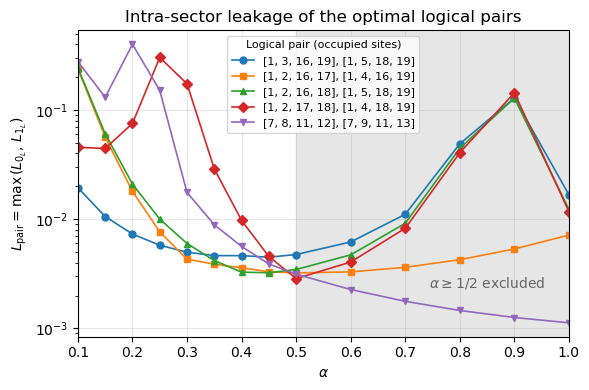

In [32]:
import matplotlib.pyplot as plt


def one_indexed(word):
    """Occupied sites 0..N-1 -> 1..N, for display only."""
    sites = []
    for i in word:
        sites.append(i + 1)
    return sites


# ---------------- alpha sweep ----------------
N, b, Jz, Jx = 20, 4, 1.0, 0.01
alphas = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

L_all = []          # L_all[k][occS] = leakage of codeword occS at alphas[k] (0-indexed keys)
winners = []        # distinct optimal logical pairs found in the sweep, in order of appearance

for alpha in alphas:
    rows = leakage_ED(N, b, alpha, Jz, Jx)

    # leakage of every codeword at this alpha
    L_here = {}
    for r in rows:
        L_here[tuple(r["occS"])] = r["L_ED"]
    L_all.append(L_here)

    # group codewords by assignment t
    groups = {}
    for r in rows:
        t = r["t"]
        if t not in groups:
            groups[t] = []
        groups[t].append(r)

    # best pair inside each t, then the best pair overall
    best_pair = None
    best_L = None
    for t in groups:
        words = groups[t]
        words.sort(key=lambda r: r["L_ED"])
        L_pair = words[1]["L_ED"]                     # worse of the two best codewords
        if best_L is None or L_pair < best_L:
            best_L = L_pair
            best_pair = sorted([tuple(words[0]["occS"]), tuple(words[1]["occS"])])

    best_pair = tuple(best_pair)                      # same pair in either order -> same key
    print(f"alpha = {alpha:.2f}  logicals = {one_indexed(best_pair[0])}, {one_indexed(best_pair[1])}  "
          f"L_pair = {best_L:.3e}")
    if best_pair not in winners:
        winners.append(best_pair)

# ---------------- plot each winning pair across the full sweep ----------------
fig, ax = plt.subplots(figsize=(6, 4))

# shade the region excluded by Requirement 3
ax.axvspan(0.5, alphas[-1], color="0.9", zorder=0)
ax.text(0.85, 0.2, r"$\alpha\geq 1/2$ excluded", transform=ax.get_xaxis_transform(),
        ha="center", va="top", color="0.4")

markers = ["o", "s", "^", "D", "v", "<", ">", "p"]
for i in range(len(winners)):
    word_a, word_b = winners[i]
    L_curve = []
    for k in range(len(alphas)):
        L_curve.append(max(L_all[k][word_a], L_all[k][word_b]))
    ax.semilogy(alphas, L_curve, marker=markers[i % len(markers)], markersize=5,
                linewidth=1.2, label=f"{one_indexed(word_a)}, {one_indexed(word_b)}")

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$L_{\rm pair}=\max\,(L_{0_L},\,L_{1_L})$")
ax.set_title(r"Intra-sector leakage of the optimal logical pairs")
ax.grid(True, which="major", alpha=0.3)
ax.set_xlim(alphas[0], alphas[-1])
ax.legend(title="Logical pair (occupied sites)", fontsize=8, title_fontsize=8, frameon=True)

fig.tight_layout()
fig.savefig("plt/Lpair_vs_alpha.pdf")
plt.show()

alpha = 0.10  logicals = [0, 1, 16, 17], [0, 3, 17, 18]  L_pair = 6.054e-01
alpha = 0.15  logicals = [0, 1, 16, 17], [0, 3, 17, 18]  L_pair = 5.270e-01
alpha = 0.20  logicals = [0, 1, 16, 17], [0, 3, 17, 18]  L_pair = 5.182e-01
alpha = 0.25  logicals = [0, 1, 15, 16], [0, 3, 15, 18]  L_pair = 4.561e-01
alpha = 0.30  logicals = [0, 1, 15, 17], [0, 4, 17, 18]  L_pair = 3.172e-01
alpha = 0.35  logicals = [0, 1, 15, 17], [0, 4, 17, 18]  L_pair = 2.700e-01
alpha = 0.40  logicals = [0, 1, 15, 17], [0, 4, 17, 18]  L_pair = 3.281e-01
alpha = 0.45  logicals = [0, 1, 16, 17], [0, 3, 17, 18]  L_pair = 2.337e-01
alpha = 0.50  logicals = [0, 1, 16, 17], [0, 3, 17, 18]  L_pair = 2.131e-01
alpha = 0.60  logicals = [6, 7, 10, 11], [6, 8, 10, 12]  L_pair = 2.104e-01
alpha = 0.70  logicals = [6, 7, 10, 11], [6, 8, 10, 12]  L_pair = 1.637e-01
alpha = 0.80  logicals = [6, 7, 10, 11], [6, 8, 10, 12]  L_pair = 1.389e-01
alpha = 0.90  logicals = [6, 7, 10, 11], [6, 8, 10, 12]  L_pair = 1.199e-01
alpha = 1.00

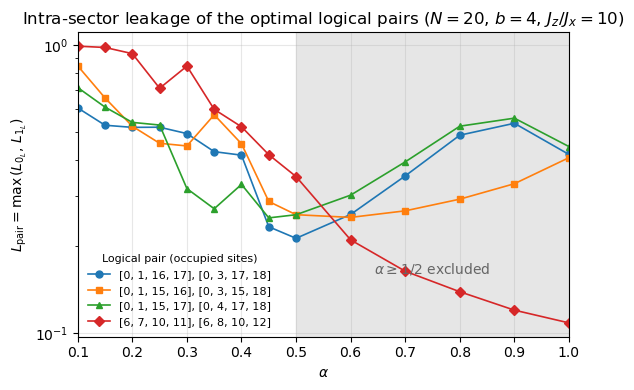

In [17]:
import matplotlib.pyplot as plt

# ---------------- alpha sweep ----------------
N, b, Jz, Jx = 20, 4, 1.0, 0.1
alphas = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

L_all = []          # L_all[k][occS] = leakage of codeword occS at alphas[k]
winners = []        # distinct optimal logical pairs found in the sweep, in order of appearance

for alpha in alphas:
    rows = leakage_ED(N, b, alpha, Jz, Jx)

    # leakage of every codeword at this alpha
    L_here = {}
    for r in rows:
        L_here[tuple(r["occS"])] = r["L_ED"]
    L_all.append(L_here)

    # group codewords by assignment t
    groups = {}
    for r in rows:
        t = r["t"]
        if t not in groups:
            groups[t] = []
        groups[t].append(r)

    # best pair inside each t, then the best pair overall
    best_pair = None
    best_L = None
    for t in groups:
        words = groups[t]
        words.sort(key=lambda r: r["L_ED"])
        L_pair = words[1]["L_ED"]                     # worse of the two best codewords
        if best_L is None or L_pair < best_L:
            best_L = L_pair
            best_pair = sorted([tuple(words[0]["occS"]), tuple(words[1]["occS"])])

    best_pair = tuple(best_pair)                      # same pair in either order -> same key
    print(f"alpha = {alpha:.2f}  logicals = {list(best_pair[0])}, {list(best_pair[1])}  "
          f"L_pair = {best_L:.3e}")
    if best_pair not in winners:
        winners.append(best_pair)

# ---------------- plot each winning pair across the full sweep ----------------
fig, ax = plt.subplots(figsize=(6, 4))

# shade the region excluded by Requirement 3
ax.axvspan(0.5, alphas[-1], color="0.9", zorder=0)
ax.text(0.75, 0.25, r"$\alpha\geq 1/2$ excluded", transform=ax.get_xaxis_transform(),
        ha="center", va="top", color="0.4")

markers = ["o", "s", "^", "D", "v", "<", ">", "p"]
for i in range(len(winners)):
    word_a, word_b = winners[i]
    L_curve = []
    for k in range(len(alphas)):
        L_curve.append(max(L_all[k][word_a], L_all[k][word_b]))
    ax.semilogy(alphas, L_curve, marker=markers[i % len(markers)], markersize=5,
                linewidth=1.2, label=f"{list(word_a)}, {list(word_b)}")

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$L_{\rm pair}=\max\,(L_{0_L},\,L_{1_L})$")
ax.set_title(rf"Intra-sector leakage of the optimal logical pairs ($N={N}$, $b={b}$, $J_z/J_x={Jz/Jx:g}$)")
ax.grid(True, which="major", alpha=0.3)
ax.set_xlim(alphas[0], alphas[-1])
ax.legend(title="Logical pair (occupied sites)", fontsize=8, title_fontsize=8, frameon=False)

fig.tight_layout()
fig.savefig("plt/Lpair_vs_alpha2.pdf")
plt.show()

alpha = 0.2
   Jz/Jx =     10  logicals = [0, 1, 16, 17], [0, 3, 17, 18]  L_pair = 5.182e-01
   Jz/Jx =     20  logicals = [0, 2, 15, 18], [0, 4, 17, 18]  L_pair = 1.697e-01
   Jz/Jx =     50  logicals = [0, 2, 15, 18], [0, 4, 17, 18]  L_pair = 2.898e-02
   Jz/Jx =    100  logicals = [0, 2, 15, 18], [0, 4, 17, 18]  L_pair = 7.314e-03
   Jz/Jx =    200  logicals = [0, 2, 15, 18], [0, 4, 17, 18]  L_pair = 1.833e-03
   Jz/Jx =    500  logicals = [0, 2, 15, 18], [0, 4, 17, 18]  L_pair = 2.934e-04
   Jz/Jx =   1000  logicals = [0, 2, 15, 18], [0, 4, 17, 18]  L_pair = 7.337e-05
alpha = 0.4
   Jz/Jx =     10  logicals = [0, 1, 15, 17], [0, 4, 17, 18]  L_pair = 3.281e-01
   Jz/Jx =     20  logicals = [0, 1, 15, 17], [0, 4, 17, 18]  L_pair = 7.448e-02
   Jz/Jx =     50  logicals = [0, 1, 15, 17], [0, 4, 17, 18]  L_pair = 1.291e-02
   Jz/Jx =    100  logicals = [0, 1, 15, 17], [0, 4, 17, 18]  L_pair = 3.273e-03
   Jz/Jx =    200  logicals = [0, 1, 15, 17], [0, 4, 17, 18]  L_pair = 8.211e-04
   J

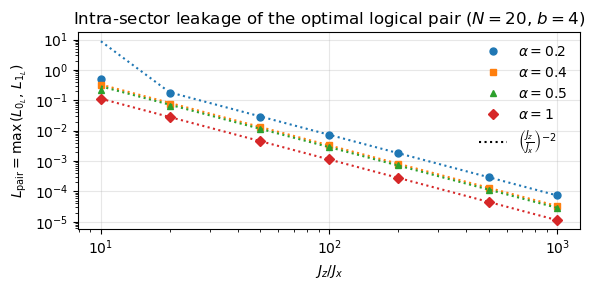

In [9]:
import matplotlib.pyplot as plt

def hop_gaps(occ, V, W, N):
    """
    Every allowed single hop from configuration occ and its energy cost, Eq. (3).

    A hop moves one excitation from occupied site i to a neighbour j = i - 1 or i + 1
    that is inside the chain and empty.

    Returns:
        list of (i, j, Delta), with Delta = E(after hop) - E(before hop)
    """
    occ_set = set(occ)
    occ_arr = np.asarray(occ)
    out = []
    for i in occ:
        others = occ_arr[occ_arr != i]                # every other excitation
        for j in (i - 1, i + 1):
            if 0 <= j < N and j not in occ_set:
                # Stark step + change in repulsion with every other excitation
                delta = V[j] - V[i] + (W[j, others] - W[i, others]).sum()
                out.append((i, j, delta))
    return out


def leakage(occ, V, W, N, Jx):
    """
    Two-level (TLS) leakage of configuration occ, Eq. (2):

        L = 2 * sum over hops of (Jx / Delta)^2

    Returns:
        (L, smallest |Delta|);  (0.0, inf) if no hop is possible
    """
    gaps = []
    for i, j, delta in hop_gaps(occ, V, W, N):
        gaps.append(abs(delta))
    if len(gaps) == 0:
        return 0.0, np.inf
    gaps = np.array(gaps)
    return 2.0 * np.sum((Jx / gaps) ** 2), gaps.min()

def best_pair(rows):
    """Best logical pair among all codewords in rows: returns (pair, L_pair)."""
    # group codewords by assignment t
    groups = {}
    for r in rows:
        t = r["t"]
        if t not in groups:
            groups[t] = []
        groups[t].append(r)

    # best pair inside each t, then the best pair overall
    pair_out = None
    L_out = None
    for t in groups:
        words = groups[t]
        words.sort(key=lambda r: r["L_ED"])
        L_pair = words[1]["L_ED"]                     # worse of the two best codewords
        if L_out is None or L_pair < L_out:
            L_out = L_pair
            pair_out = sorted([tuple(words[0]["occS"]), tuple(words[1]["occS"])])
    return tuple(pair_out), L_out


# ---------------- Jz sweep, one curve per alpha ----------------
N, b, Jx = 20, 4, 0.01
alphas = [0.2, 0.4, 0.5, 1.0]
Jzs = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]           # Jz/Jx = 10 ... 1000

Jz_over_Jx = []
for Jz in Jzs:
    Jz_over_Jx.append(Jz / Jx)

fig, ax = plt.subplots(figsize=(6, 3))
markers = ["o", "s", "^", "D", "v", "<", ">", "p"]

for i in range(len(alphas)):
    alpha = alphas[i]

    # ED: best pair and its leakage at each Jz
    L_curve = []
    pairs_used = []
    print(f"alpha = {alpha}")
    for Jz in Jzs:
        rows = leakage_ED(N, b, alpha, Jz, Jx)
        pair, L_pair = best_pair(rows)
        L_curve.append(L_pair)
        pairs_used.append(pair)
        print(f"   Jz/Jx = {Jz / Jx:6.0f}  logicals = {list(pair[0])}, {list(pair[1])}  "
              f"L_pair = {L_pair:.3e}")

    # TLS prediction for the same pairs: L = 2 sum_k (Jx / Delta_k)^2 per codeword
    L_tls = []
    for k in range(len(Jzs)):
        V, W = get_V_W(N, alpha, Jzs[k])
        L_a = leakage(list(pairs_used[k][0]), V, W, N, Jx)[0]
        L_b = leakage(list(pairs_used[k][1]), V, W, N, Jx)[0]
        L_tls.append(max(L_a, L_b))

    # draw ED first, then TLS in the same color
    if alpha >= 0.5:
        style = ""                                  # excluded by Requirement 3
    else:
        style = ""
    ax.loglog(Jz_over_Jx, L_curve, linestyle=style, marker=markers[i % len(markers)],
              markersize=5, linewidth=1.2, label=rf"$\alpha={alpha:g}$")
    color = ax.lines[-1].get_color()
    ax.loglog(Jz_over_Jx, L_tls, linestyle=":", color=color, linewidth=1.5)

# one legend entry explaining the dotted lines
ax.plot([], [], linestyle=":", color="k", linewidth=1.5, label=r"$\left(\frac{J_z}{J_x}\right)^{-2}$")

ax.set_xlabel(r"$J_z/J_x$")
ax.set_ylabel(r"$L_{\rm pair}=\max\,(L_{0_L},\,L_{1_L})$")
ax.set_title(rf"Intra-sector leakage of the optimal logical pair ($N={N}$, $b={b}$)")
ax.grid(True, which="major", alpha=0.3)
ax.legend(fontsize=10, frameon=False)

fig.tight_layout()
fig.savefig("plt/Lpair_vs_Jz_alphas.pdf")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def pair_label(occS, N):
    """
    Occupied sites (0-indexed) -> N-independent description in mirror-pair labels:
        A : active pairs, counted from the edge (pair p = sites p and N-1-p)
        S : active pairs with the excitation on the LEFT site
    """
    A = []
    S = []
    for i in occS:
        p = min(i, N - 1 - i)
        A.append(p)
        if i < N // 2:
            S.append(p)
    return tuple(sorted(A)), tuple(sorted(S))


def one_indexed(pairs):
    """Pair labels 0.. -> 1.., for display only."""
    out = []
    for p in pairs:
        out.append(p + 1)
    return out


# ---------------- N sweep ----------------
b, alpha, Jz, Jx = 4, 0.4, 1.0, 0.01
Ns = [12, 14, 16, 18, 20, 22, 24, 26, 28]

L_all = []          # L_all[k][(A, S)] = leakage of codeword (A, S) at Ns[k]
winners = []        # distinct optimal logical pairs (A, S, T), in order of appearance

for N in Ns:
    rows = leakage_ED(N, b, alpha, Jz, Jx)

    # leakage of every codeword, keyed by its pair description
    L_here = {}
    for r in rows:
        L_here[pair_label(r["occS"], N)] = r["L_ED"]
    L_all.append(L_here)

    # group codewords by assignment t
    groups = {}
    for r in rows:
        t = r["t"]
        if t not in groups:
            groups[t] = []
        groups[t].append(r)

    # best pair inside each t, then the best pair overall
    best_key = None
    best_L = None
    for t in groups:
        words = groups[t]
        words.sort(key=lambda r: r["L_ED"])
        L_pair = words[1]["L_ED"]                     # worse of the two best codewords
        if best_L is None or L_pair < best_L:
            best_L = L_pair
            A, S0 = pair_label(words[0]["occS"], N)
            A, S1 = pair_label(words[1]["occS"], N)
            S0, S1 = sorted([S0, S1])                 # same pair in either order -> same key
            best_key = (A, S0, S1)

    A, S0, S1 = best_key
    print(f"N = {N:2d}  A = {one_indexed(A)}  S = {one_indexed(S0)}  T = {one_indexed(S1)}  "
          f"L_pair = {best_L:.3e}")
    if best_key not in winners:
        winners.append(best_key)

# ---------------- plot each winning pair across all N ----------------
fig, ax = plt.subplots(figsize=(6, 4))

markers = ["o", "s", "^", "D", "v", "<", ">", "p"]
for i in range(len(winners)):
    A, S0, S1 = winners[i]
    L_curve = []
    for k in range(len(Ns)):
        word_a = (A, S0)
        word_b = (A, S1)
        if word_a in L_all[k] and word_b in L_all[k]:
            L_curve.append(max(L_all[k][word_a], L_all[k][word_b]))
        else:
            L_curve.append(np.nan)                    # pair does not fit in this N
    ax.semilogy(Ns, L_curve, marker=markers[i % len(markers)], markersize=5, linewidth=1.2,
                label=f"A={one_indexed(A)}, S={one_indexed(S0)}, T={one_indexed(S1)}")

ax.set_xlabel(r"$N$")
ax.set_ylabel(r"$L_{\rm pair}=\max\,(L_{0_L},\,L_{1_L})$")
ax.set_title(rf"Intra-sector leakage of the optimal logical pairs ($b={b}$, $\alpha={alpha}$, $J_z/J_x={Jz/Jx:g}$)")
ax.grid(True, which="major", alpha=0.3)
ax.set_xticks(Ns)
ax.legend(title="Logical pair (mirror pairs from the edge)", fontsize=8, title_fontsize=8, frameon=True)

fig.tight_layout()
fig.savefig("plt/Lpair_vs_N.pdf")
plt.show()

N = 12  A = [1, 2, 3, 4]  S = [1, 2]  T = [1, 4]  L_pair = 1.934e-02
N = 14  A = [1, 2, 3, 4]  S = [1, 2]  T = [1, 4]  L_pair = 6.724e-03
N = 16  A = [1, 2, 3, 4]  S = [1, 2]  T = [1, 4]  L_pair = 4.149e-03
N = 18  A = [1, 2, 3, 5]  S = [1, 2]  T = [1, 5]  L_pair = 4.011e-03
N = 20  A = [1, 2, 3, 5]  S = [1, 2]  T = [1, 5]  L_pair = 3.273e-03
N = 22  A = [1, 2, 4, 5]  S = [1, 2]  T = [1, 4]  L_pair = 3.062e-03
N = 24  A = [1, 2, 4, 5]  S = [1, 2]  T = [1, 4]  L_pair = 2.679e-03


# Codeword optimization for the imbalance code

This notebook finds the best encoding of a logical qubit in the confined long-range chain. An encoding is a choice of

1. the excitation sector $b$,
2. the **pair assignment** $t$: which mirror pairs are empty, active, or doubly occupied,
3. the **logical pair** $(S,T)$: which two codewords become $|0_L\rangle$ and $|1_L\rangle$.

Every encoding passes the same symmetry checks. They differ in how strongly the Hamiltonian protects them, and that is what we compute.

**Plan of the notebook**

| § | What | Check |
|---|---|---|
| 1 | $V$, $W$ and configuration energies $E(c)$ | matches QuTiP $H_{\rm eff}$ exactly |
| 2 | The codespace as a list of codewords | $\dim\mathcal C=\tfrac12\binom{2K}{K}$ |
| 3 | Hop gaps and leakage $L(c)$ | worked example |
| 4 | Pair quantities $d_X$, $h(S,T)$, $\Delta E_{ST}$ | worked example |
| 5 | Exhaustive optimization | ranked table |
| 6 | Exact verification by ED | leakage formula vs. exact dynamics |
| 7 | Sweep over $\alpha$ | best encoding vs. $\alpha$ |

**Conventions**

- Sites $i=0,\dots,N-1$. The mirror of site $i$ is $N-1-i$.
- Mirror pair $p$ is the sites $(p,\;N-1-p)$, for $p=0,\dots,N/2-1$.
- Excitation = occupied site, $\hat n_i=|1\rangle\langle1|$ (QuTiP's `basis(2,1)`).

**Not included here:** sector leakage ($b\to b\pm1,b\pm2$), which depends only on $(N,\alpha,b)$ and enters the outer loop over $b$; and open-system noise.

## 1. The Hamiltonian inside a sector

For $J_z\gg J_x,B_x$, sector confinement removes particle-number-changing processes, and inside sector $b$ the dynamics is

$$H^b_{\rm eff}=T+U,\qquad T=J_x\sum_{i=0}^{N-2}\big(\hat a_i^\dagger\hat a_{i+1}+{\rm h.c.}\big),\qquad U=\sum_iV(i)\,\hat n_i+\sum_{i<j}W(i,j)\,\hat n_i\hat n_j,$$

with

$$V(i)=-2J_z\sum_{j\ne i}|i-j|^{-\alpha},\qquad W(i,j)=4J_z\,|i-j|^{-\alpha}.$$

$U$ is diagonal in the **configuration basis** $|c\rangle$, where $c$ lists the occupied sites:

$$E(c)=\sum_{i\in c}V(i)+\sum_{i<j\in c}W(i,j).\tag{1}$$

$T$ is purely off-diagonal: it connects $c$ to configurations one hop away, with matrix element exactly $J_x$.

Two facts we will use throughout:

- **Scaling.** $V,W\propto J_z$, so $E(c)=J_z\,\varepsilon(c;N,\alpha)$. Changing $J_z$ rescales every gap but does not change which encoding is best.
- **Mirror symmetry.** $V(N-1-i)=V(i)$ and $W$ depends only on $|i-j|$, so a configuration and its mirror image have the same energy.

### 1a. $V$ and $W$ as arrays

`W` is an $N\times N$ matrix. Setting the diagonal distance to infinity makes $|i-i|^{-\alpha}=0$ automatically. Then $V(i)$ is just $-\tfrac12$ times the row sum of `W`, since $-\tfrac12\cdot4J_z=-2J_z$.

get_V_W precomputes a table of coefficients once, and config_energy reads off the entries for whichever sites are occupied.

In [ ]:
def get_V_W(N, alpha, Jz):
    """
    Precompute the table of coefficients for the confining potential V and the pair repulsion W:

        V(i)   = -2 Jz * sum_{j != i} |i-j|^(-alpha)      (array of length N)
        W(i,j) =  4 Jz * |i-j|^(-alpha)                   (N x N matrix, W[i,i] = 0)
    """
    # np.arange(N) is the array [0, 1, ..., N-1] of site labels.
    #
    # np.subtract.outer(a, b) makes the matrix of all differences a[i] - b[j].
    # For N = 4:
    #     [[ 0 -1 -2 -3]
    #      [ 1  0 -1 -2]
    #      [ 2  1  0 -1]
    #      [ 3  2  1  0]]
    # np.abs makes it the distance matrix r[i, j] = |i - j|.
    # .astype(float) converts integers to floats, so we can put infinity in it next.
    r = np.abs(np.subtract.outer(np.arange(N), np.arange(N))).astype(float)

    # The diagonal is r[i, i] = 0, and 0 ** (-alpha) would be infinite.
    # A site doesn't interact with itself, so we want W[i, i] = 0 instead.
    # Setting the diagonal distance to infinity does exactly that: inf ** (-alpha) = 0.
    np.fill_diagonal(r, np.inf)

    # Elementwise power: every entry of r is raised to -alpha, then multiplied by 4 Jz.

    W = 4.0 * Jz * r ** (-alpha)

    # On-site confining potential V(i):
    # -0.5 * W.sum(axis=1) equals -2 * Jz * sum_{j != i} |i-j|^(-alpha)
    V = -0.5 * W.sum(axis=1)

    return V, W


def config_energy(occ, V, W):
    """
    Diagonal energy of a configuration,

        E(c) = sum_{i in c} V(i)  +  sum_{i < j in c} W(i, j)

    occ : list of occupied sites, e.g. [4, 5, 6]

    will return V[4]+V[5]+V[6]+W[4,5]+W[4,6]+W[5,6]
    """
    # Turn the list into a numpy array so it can be used to index V and W.
    occ = np.asarray(occ)

    # V[occ] picks out the entries of V at the occupied sites and .sum() adds them: 
    # this is the potential-energy term.
    potential = V[occ].sum()

    # np.ix_(occ, occ) selects the rows AND columns in occ, i.e. the sub-matrix
    # of W restricted to occupied sites. For occ = [4, 5]:
    #     [[W(4,4) W(4,5)]      [[0. 4.]
    #      [W(5,4) W(5,5)]]  =   [4. 0.]]
    # Summing it gives W(4,5) + W(5,4) = 2 W(4,5): every pair is counted twice
    # (once as (i,j), once as (j,i)), and the diagonal is 0.
    # The factor 0.5 removes the double counting -> sum over i < j only.
    repulsion = 0.5 * W[np.ix_(occ, occ)].sum()

    return potential + repulsion


# ---------------- example ----------------

# V, W = get_V_W(6, 0, 1.0)              # N = 6 sites, alpha = 0.5, Jz = 1
# print("V =", np.round(V, 4))             # np.round(..., 4): show 4 decimals

# # Configuration 000011: excitations on sites 4 and 5.
# #   V(4) + V(5) + W(4,5) = -7.5689 + (-6.4633) + 4.0 = -10.0323
# print("E([4,5]) =", round(config_energy([4, 5], V, W), 4))

**What to see:** $V$ is least negative at sites 0 and 5. The edges are the **maxima** of the convex well. Moving toward the center lowers the energy.


### 1b. Check against QuTiP

`config_energy` is a hand-written shortcut, so we check it against the full operator. We build $H_{\rm eff}$ in QuTiP on all $2^N$ states, keep the $b$-excitation block, and compare its diagonal with Eq. (1) for every configuration.

`site_op` puts a single-site operator on site $i$ and identities elsewhere: $\mathbb1\otimes\cdots\otimes\hat O\otimes\cdots\otimes\mathbb1$. Site 0 is the leftmost bit of the basis index.

In [ ]:
def site_op(op, i, N):
    ops = [qt.qeye(2)] * N
    ops[i] = op
    return qt.tensor(ops)


def build_Heff_qutip(N, alpha, Jz, Jx):
    """
    H_eff = T + U built WITHOUT V and W:

        T = Jx * sum_i (a_i^dag a_{i+1} + h.c.)                  hopping
        U = sum_{i<j} Jz/|i-j|^alpha * sz_i sz_j  -  E0          spin Ising term minus constant
    """
    a  = [site_op(qt.destroy(2), i, N) for i in range(N)]   # a_i: removes an excitation at i
    sz = [site_op(qt.sigmaz(), i, N) for i in range(N)]     # sigma^z_i: +1 empty, -1 occupied

    H = 0

    # T: nearest-neighbour hopping, open chain (bonds 0-1, 1-2, ..., (N-2)-(N-1))
    for i in range(N - 1):
        H += Jx * (a[i].dag() * a[i + 1] + a[i + 1].dag() * a[i])

    # U: the original long-range Ising term, accumulating the constant E0 as we go
    E0 = 0.0
    for i in range(N):
        for j in range(i + 1, N):                            # each pair once (j > i)
            Jij = Jz / abs(i - j) ** alpha                   # coupling Jz / |i-j|^alpha
            H  += Jij * sz[i] * sz[j]
            E0 += Jij                                        # E0 = sum_{i<j} Jz / |i-j|^alpha

    # subtract E0 times the identity, so U matches sum V n + sum W n n with no offset
    # (qt.qeye([2]*N) is the identity on N spins, with the same dims as H)
    H -= E0 * qt.qeye([2] * N)

    return H


def occupied(k, N):
    # basis index k -> list of occupied sites, e.g. 3 -> '000011' -> [4, 5]
    return [i for i, bit in enumerate(format(k, f"0{N}b")) if bit == "1"]


N, alpha, Jz, Jx, b = 3, 0.5, 1.0, 0.1, 2
H = build_Heff_qutip(N, alpha, Jz, Jx)
Ntot = sum(site_op(qt.num(2), i, N) for i in range(N))

idx = [k for k in range(2**N) if bin(k).count("1") == b]     # basis states with b excitations
Hb = H.full()[np.ix_(idx, idx)]                              # the sector-b block


V, W = get_V_W(N, alpha, Jz)
E_fast = np.array([config_energy(occupied(k, N), V, W) for k in idx])

# print("Hermitian:              ", H.isherm)
# print("[H, Ntot] = 0:          ", (H * Ntot - Ntot * H).norm())
# print("[H, R] = 0:             ", (H.permute(list(range(N))[::-1]) - H).norm())
print("sector dimension:       ", Hb.shape[0], "=", comb(N, b))
print("b projected Hamiltonian", Hb)
print("max |E_fast - diag(H)|: ", np.abs(E_fast - np.diag(Hb).real).max())# is within numerical precision

sector dimension:        3 = 3
b projected Hamiltonian [[-3.41421356+0.j  0.1       +0.j  0.        +0.j]
 [ 0.1       +0.j -4.        +0.j  0.1       +0.j]
 [ 0.        +0.j  0.1       +0.j -3.41421356+0.j]]
max |E_fast - diag(H)|:  4.440892098500626e-16


**Expected:** `True`, `0.0`, `0.0`, `15 = 15`, and an error around $10^{-15}$.

- $[H,\hat N_{\rm tot}]=0$: hopping moves excitations but never creates them, so $b$ is conserved.
- $[H,R]=0$: `.permute(reversed order)` mirrors the chain. Reflection is an exact symmetry.
- The last line says Eq. (1) is exactly the diagonal of $H_{\rm eff}$. From here on we use `config_energy` and never build the $2^N$ matrix again.

## 2. The codespace as a list

**Pair assignment.** $t=(t_0,\dots,t_{N/2-1})$ with $t_p\in\{0,1,2\}$ and $\sum_pt_p=b$. The **active pairs** are $A=\{p:t_p=1\}$, with $|A|=2K$.

**Codewords.** Each active pair holds one excitation, on its left or its right site. So a configuration is fully specified by $S\subseteq A$, the active pairs whose excitation is on the **left**.

- $M=0$ forces exactly $K$ left-occupied pairs: $|S|=K$.
- Reflection maps $S\to S^c=A\setminus S$. The $R$-even codeword is

$$|v_S\rangle=\tfrac1{\sqrt2}\big(|S\rangle+|S^c\rangle\big),\qquad |v_S\rangle=|v_{S^c}\rangle,\qquad \dim\mathcal C=\tfrac12\binom{2K}{K}.$$

Because $S$ and $S^c$ give the same codeword, we keep only one of them: the one containing the first active pair.

Since $E(S)=E(S^c)$ by mirror symmetry, every codeword is an exact eigenstate of $U$. Without hopping, codewords would be frozen forever.

In [ ]:
import itertools
from collections.abc import Set
from math import comb
import numpy as np

def codewords(t: tuple[int, ...]) -> tuple[list[frozenset[int]], list[int], int]:
    """
    Args:
            t : pair assignment, t[p] in {0, 1, 2}, e.g. (1,1,1,1,0,0)

    List all codewords |v_S> for pair assignment t. e.g

    

    Returns:
        words : one label S per codeword, e.g. [frozenset({0,1}), frozenset({0,2}), frozenset({0,3})]
        A     : active pairs (t[p] == 1), e.g. [0, 1, 2, 3]
        K     : number of left-occupied active pairs, |S| = K, e.g. 2
    """
    # active pairs: every pair p holding exactly one excitation
    # (list comprehension: "keep p for each (p, tp) in enumerate(t) if tp == 1")
    A = [p for p, tp in enumerate(t) if tp == 1]

    # M = 0 needs equal numbers of left and right excitations among active pairs,
    # so exactly half of them are left-occupied.  // is integer division.
    K = len(A) // 2

    # itertools.combinations(A, K) yields every way to pick K pairs out of A,
    # e.g. combinations([0,1,2,3], 2) -> (0,1) (0,2) (0,3) (1,2) (1,3) (2,3).
    #
    # S and its complement A \ S give the SAME codeword, because
    # |v_S> = (|S> + |S^c>)/sqrt(2) = |v_{S^c}>.  Of each such pair exactly one
    # contains the first active pair A[0], so "if A[0] in S" keeps one of each:
    #   kept:    (0,1) (0,2) (0,3)
    #   dropped: (2,3) (1,3) (1,2)   <- complements of the kept ones
    #
    # frozenset turns the tuple into an (immutable) set, so we can later use
    # set operations like "p in S", A - S, S & T, S ^ T.
    words = [frozenset(S) for S in itertools.combinations(A, K) if A[0] in S]

    return words, A, K

def config_from_S(S: Set[int], t: tuple[int, ...], N: int) -> list[int]:
    """
    Turn a codeword label S into the list of occupied sites of |S>.

    Args:
        S : active pairs whose excitation sits on the LEFT site, e.g. frozenset({0, 2})
        t : pair assignment, t[p] in {0, 1, 2} = excitations in pair p, e.g. (1,1,1,1,0,0)
        N : number of sites, with len(t) == N // 2, e.g. 12

    Returns:
        sorted list of occupied sites, e.g. [0, 2, 8, 10]

    Example (N = 12, t = (1,1,1,1,0,0), S = {0, 2}):
        pair 0 active, in S      -> left site 0
        pair 1 active, not in S  -> right site 10
        pair 2 active, in S      -> left site 2
        pair 3 active, not in S  -> right site 8
        pairs 4, 5 empty         -> nothing
        result: [0, 2, 8, 10]    i.e.  101000001010
    """
    occ = []                                     # occupied sites, filled pair by pair

    # enumerate(t) gives (index, value) pairs: (0, t[0]), (1, t[1]), ...
    # so p is the pair number and tp is how many excitations pair p holds
    for p, tp in enumerate(t):

        # the two sites of mirror pair p: site p on the left, its mirror N-1-p on the right
        L, R = p, N - 1 - p

        if tp == 2:
            # doubly occupied pair: both sites are occupied, no choice to make
            occ += [L, R]                        # += on a list appends both elements

        elif tp == 1:
            # active pair: exactly one excitation, and S decides which side
            # "L if p in S else R" is Python's one-line if/else:
            #   p in S     -> excitation on the left site
            #   p not in S -> excitation on the right site
            occ.append(L if p in S else R)

        # tp == 0: empty pair, nothing to add

    # sort so the same configuration always gives the same list
    # (needed later when we look configurations up or compare them)
    return sorted(occ)






In [ ]:
N=12
t = (1, 1, 0, 1, 1, 0)                 # pairs 0-3 active (edges), pairs 4-5 empty (bulk)
words, A, K = codewords(t)             # unpack the three returned values
print(words)
# print(A, K)    # [0, 1, 3] 1
print(words[1])
#now since the codewords are computed, we can feed them into config_from_S()
print(config_from_S(words[1], t, N))

# print(codestrings(words[1],t,N, A))

[frozenset({0, 1}), frozenset({0, 3}), frozenset({0, 4})]
frozenset({0, 3})
[0, 3, 7, 10]


In [ ]:
# ---------------- example ----------------

N, alpha, Jz = 12, 0.5, 1.0
t = (1, 1, 1, 1, 0, 0)                 # pairs 0-3 active (edges), pairs 4-5 empty (bulk)
words, A, K = codewords(t)             # unpack the three returned values
V, W = get_V_W(N, alpha, Jz)

# check the number of codewords against dim C = (1/2) * binomial(2K, K)
# (inside an f-string, {...} is replaced by the value of the expression)
print(f"A = {A}, K = {K}, dim C = {len(words)} (formula: {comb(2*K, K)//2})\n")

for S in words:
    # occupied sites of |S> and of its mirror image |S^c>
    occS  = config_from_S(S, t, N)
    occSc = config_from_S(frozenset(A) - S, t, N)      # A - S on sets = A \ S

    # bitstring picture: '1' on occupied sites, '0' elsewhere, site 0 on the left
    # ("".join glues the characters together into one string)
    bits  = "".join("1" if i in occS else "0" for i in range(N))

    # imbalance M = (# excitations in right half) - (# in left half)
    # "i >= N // 2" is True/False; sum() counts the Trues
    M     = sum(i >= N // 2 for i in occS) - sum(i < N // 2 for i in occS)

    # E(S) and E(S^c) should be equal by mirror symmetry
    # (:.4f in an f-string prints the number with 4 decimals)
    print(sorted(S), bits, f"M = {M}",
          f"E(S) = {config_energy(occS, V, W):.4f}", f"E(S^c) = {config_energy(occSc, V, W):.4f}")

A = [0, 1, 2, 3], K = 2, dim C = 3 (formula: 3)

[0, 1] 110000001100 M = 0 E(S) = -35.1489 E(S^c) = -35.1489
[0, 2] 101000001010 M = 0 E(S) = -37.4394 E(S^c) = -37.4394
[0, 3] 100100000110 M = 0 E(S) = -36.7701 E(S^c) = -36.7701


**What to see:** one excitation per active pair, two on each half, nothing in the bulk; $M=0$ in every row; $E(S)=E(S^c)$ in every row.

**Listing all pair assignments.** The search must not assume edge placement, so we generate every assignment with $\sum_pt_p=b$ and at least two codewords ($K\ge2$). With $d$ doubly occupied pairs there are $a=b-2d$ active pairs, giving $\binom{m}{d}\binom{m-d}{a}$ assignments for $m=N/2$ pairs.

In [ ]:
def pair_assignments(N: int, b: int, K_min: int = 2):
    """
    Generate every pair assignment t for b excitations on N sites, with no doubly
    occupied pairs.

    Each mirror pair p = (p, N-1-p) holds:
        t[p] = 0  empty pair
        t[p] = 1  active pair (one excitation, left or right: this is where the code lives)

    Doubly occupied pairs (t[p] = 2) are excluded. They add no codewords and no d_X,
    but cost 2 excitations each, so they would push a code with a active pairs from
    sector b = a into the higher sector b = a + 2d, which leaks more.

    So every excitation sits on an active pair (a = b), and the constraints are:
        b even                       M = 0 needs b/2 left, b/2 right
        b >= 2 * K_min               at least K_min left-occupied pairs; K_min = 2
                                     guarantees >= 3 codewords
        b <= N/2                     at most one excitation per pair

    No assumption about WHERE the active pairs sit: every placement is generated.

    Args:
        N     : number of sites (even), e.g. 12
        b     : number of excitations, e.g. 4
        K_min : minimum number of left-occupied active pairs (default 2)

    Yields:
        t : tuple of length N/2 with entries in {0, 1}, one assignment at a time

    Example (N = 12, b = 4 -> 6 pairs, choose 4 active):
        (1, 1, 1, 1, 0, 0), (1, 1, 1, 0, 1, 0), ..., (0, 0, 1, 1, 1, 1)    15 assignments

    Count: C(N/2, b).
    """
    m = N // 2                                   # number of mirror pairs

    # nothing to generate if the sector can't host an M = 0 code
    if b % 2 or b < 2 * K_min or b > m:
        return

    # choose which b pairs are active; the rest are empty
    for actives in itertools.combinations(range(m), b):
        t = [0] * m
        for p in actives:
            t[p] = 1
        yield tuple(t)


# Count assignments without storing them:
# "sum(1 for _ in gen)" adds 1 for every t the generator produces.
# ("_" is the conventional name for a loop variable we don't use.)
# {N_:3d} pads the number to width 3, {...:7d} to width 7, so the columns line up.
for N_, b_ in [(20, 4), (20, 8), (60, 4), (100, 4)]:
    print(f"N = {N_:3d}, b = {b_}: {sum(1 for _ in pair_assignments(N_, b_)):7d} assignments")

N =  20, b = 4:     210 assignments
N =  20, b = 8:      45 assignments
N =  60, b = 4:   27405 assignments
N = 100, b = 4:  230300 assignments


## 3. Leakage from a codeword

### 3a. Where the formula comes from

Take a configuration $|c\rangle$ with hop neighbors $|k\rangle$, $\langle k|T|c\rangle=J_x$, and gaps $\Delta_k=E(k)-E(c)$. If every hop is off-resonant, $|\Delta_k|\gg J_x$, first-order perturbation theory gives the eigenstate connected to $|c\rangle$:

$$|\tilde n_c\rangle=|c\rangle-\sum_k\frac{J_x}{\Delta_k}|k\rangle+\dots,\qquad |\langle c|\tilde n_c\rangle|^2=1-\sum_k\Big(\frac{J_x}{\Delta_k}\Big)^2+O(J_x^4/\Delta^4).$$

The long-time-averaged return probability is $\overline P(c)=\sum_n|\langle n|c\rangle|^4$. The $\tilde n_c$ term gives $1-2\sum_k(J_x/\Delta_k)^2$, and all others are $O(J_x^4)$. So

$$\boxed{L(c)=1-\overline P(c)=2\sum_{k}\Big(\frac{J_x}{\Delta_k}\Big)^2}\tag{2}$$

This is the paper's two-level lemma, $2(\lambda/\Delta)^2$ per channel, summed over channels. For $K\ge2$ the neighbors of $S$ and $S^c$ don't overlap, so $L(v_S)=L(S)$.

**Why the sum and not the smallest gap:** $2(J_x/\Delta_{\min})^2\le L\le|\mathcal N|\cdot2(J_x/\Delta_{\min})^2$, where $|\mathcal N|\le2b$ is the number of hops. A codeword with many moderately soft hops can leak more than one with a single softer hop. §6 shows this happening.

### 3b. The hop gap

When one excitation hops $i\to j=i\pm1$, only the terms involving it change:

$$\Delta_{i\to j}(c)=\underbrace{V(j)-V(i)}_{\text{Stark step}}+\underbrace{\sum_{k\in c,\,k\ne i}\big[W(j,k)-W(i,k)\big]}_{\text{change in repulsion}}.\tag{3}$$

The Stark step pulls excitations toward the center (negative in the left half). The repulsion term pushes them away from each other (positive when moving toward a neighbor). When the two nearly cancel, the hop is resonant even for $J_x\ll J_z$.

A hop is allowed only if $j$ is inside the chain and empty (hard-core bosons).

In [ ]:
def hop_gaps(occ, V, W, N):
    """
    List every allowed single hop from configuration occ and its energy cost, Eq. (3).

    A hop moves one excitation from occupied site i to a neighbor j = i +/- 1
    that is inside the chain and empty.

    Args:
        occ : occupied sites, e.g. [0, 1, 8, 9]
        V   : on-site potential, shape (N,)
        W   : pairwise interaction, shape (N, N)
        N   : number of sites

    Returns:
        list of (i, j, Delta), with Delta = E(after hop) - E(before hop)
                             = V[j] - V[i] + sum_k (W[j,k] - W[i,k]),  k over the other excitations

    Example (N = 12, occ = [0, 1, 8, 9]):
        allowed hops 1->2, 8->7, 9->10  (the rest are blocked by the edge or occupied sites)
    """
    occ_set, occ_arr = set(occ), np.asarray(occ)
    out = []
    for i in occ:
        others = occ_arr[occ_arr != i]
        for j in (i - 1, i + 1):
            if 0 <= j < N and j not in occ_set:
                delta = V[j] - V[i] + (W[j, others] - W[i, others]).sum()
                out.append((i, j, delta))
    return out


def leakage(occ, V, W, N, Jx):
    """
    Perturbative leakage of configuration occ under hopping Jx, Eq. (2):
        leakage = 2 * sum over hops of (Jx / |Delta|)^2

    Args:
        occ, V, W, N : as in hop_gaps
        Jx           : hopping strength

    Returns:
        (leakage, min_gap)
            leakage : float, smaller = better protected
            min_gap : smallest |Delta|; the formula is valid only if Jx << min_gap
        (0.0, inf) if no hop is possible.

    A resonant hop (Delta = 0) gives a divide-by-zero, so leakage = inf:
    the configuration is not protected.
    """
    gaps = np.array([abs(g) for (_, _, g) in hop_gaps(occ, V, W, N)])
    if len(gaps) == 0:
        return 0.0, np.inf
    return 2.0 * np.sum((Jx / gaps) ** 2), gaps.min()


#########Example#############

N, alpha, Jz, Jx = 20, 0.5, 100.0, 1.0
t = (1, 1, 1, 1,1) + (0,) * 5
words, A, K = codewords(t)
V, W = get_V_W(N, alpha, Jz)

for S in words:
    occ = config_from_S(S, t, N)
    Leak, gmin = leakage(occ, V, W, N, Jx)
    hops = [(int(i), int(j), round(float(g), 1)) for (i, j, g) in hop_gaps(occ, V, W, N)]
    print(f"S = {sorted(S)}  occ = {occ}")
    print(f"   hops (from, to, gap): {hops}")
    print(f"   Leak = {Leak:.3e}   smallest gap = {gmin:.1f} Jx\n")

S = [0, 1]  occ = [0, 1, 15, 16, 17]
   hops (from, to, gap): [(1, 2, -200.5), (15, 14, -199.2), (17, 18, -80.5)]
   Leak = 4.088e-04   smallest gap = 80.5 Jx

S = [0, 2]  occ = [0, 2, 15, 16, 18]
   hops (from, to, gap): [(0, 1, -27.3), (2, 1, 200.8), (2, 3, -107.0), (15, 14, -177.7), (16, 17, 60.4), (18, 17, 80.8), (18, 19, 65.8)]
   Leak = 4.285e-03   smallest gap = 27.3 Jx

S = [0, 3]  occ = [0, 3, 15, 17, 18]
   hops (from, to, gap): [(0, 1, -92.9), (3, 2, 107.4), (3, 4, -68.1), (15, 14, -111.9), (15, 16, 211.3), (17, 16, -59.9), (18, 19, 0.2)]
   Leak = 3.941e+01   smallest gap = 0.2 Jx

S = [0, 4]  occ = [0, 4, 16, 17, 18]
   hops (from, to, gap): [(0, 1, -114.2), (4, 3, 68.7), (4, 5, -45.2), (16, 15, -210.6), (18, 19, -21.1)]
   Leak = 6.099e-03   smallest gap = 21.1 Jx



**What to see:** $\{0,2\}$ does not have the smallest minimum gap, but it has 7 hops instead of 3 or 5, and it leaks the most. A smallest-gap ranking would get this wrong.

Also check the scaling: rerun with `Jz = 10.0`. Every gap shrinks by 10 and every $L$ grows by 100, but the **ranking** of codewords doesn't change. Only $N$, $\alpha$ and $t$ decide the ranking.

## 4. Choosing the logical pair

For $|0_L\rangle=|v_S\rangle$, $|1_L\rangle=|v_T\rangle$ we need three quantities.

**X-distance** (static Pauli-$X$ errors, from the paper):

$$d_X=2\min\big(|S\triangle T|,\;|S\triangle T^c|\big).$$

**Hop distance** $h(S,T)$: the minimum number of coherent hops turning configuration $S$ into $T$ or $T^c$. Hard-core bosons can't pass each other in 1D, so the optimal path matches the sorted positions:

$$h=\sum_k|x_k-y_k|,\qquad x,y\ \text{sorted occupied sites}.$$

This is **not** $d_X$. Hopping can move an excitation to a *neighboring* active pair in one step, so two codewords at $d_X=4$ can be only 2 hops apart. At order $h$ the hopping generates a direct logical coupling $J_{\rm eff}\propto J_x^h/J_z^{h-1}$, and the time-averaged logical transfer is

$$\overline P_{S\to T}\approx2\Big(\frac{J_{\rm eff}}{\Delta E_{ST}}\Big)^2\propto\Big(\frac{J_x}{J_z}\Big)^{2h}.\tag{4}$$

**Energy mismatch** $\Delta E_{ST}=E(S)-E(T)$ sets the logical phase rate. A drift $\delta J_z/J_z=\epsilon$ produces a phase error $\epsilon\,\Delta E_{ST}\,t$. Making $\Delta E_{ST}=0$ removes that, but then Eq. (4) breaks down and the qubit Rabi-flips at rate $J_{\rm eff}$. **So degeneracy is only safe when $h$ is large.**

In [ ]:
print(t)

t=(1, 1, 1, 1, 1, 1, 0, 0, 0, 0)

(1, 1, 1, 1, 1, 0, 0, 0, 0, 0)


In [ ]:
def d_X(S, T, A):
    """
    So d_X = 2 * (number of differing pairs),
    minimized over the two branches of |v_T>.

    Example (A = [0, 1, 2, 3]):

        S = {0,1}, T = {0,2}:  S ^ T = {1,2},  S ^ T^c = {0,3}  ->  d_X = 2 * 2 = 4
    """
    Tc = frozenset(A) - T                            # mirror branch of |v_T>
    # ^ = symmetric difference: pairs in one set but not the other,
    # i.e. the active pairs whose excitation sits on opposite sides in S and T
    return 2 * min(len(S ^ T), len(S ^ Tc))


def hop_distance(occ1, occ2):
    """
    Fewest nearest-neighbor hops that turn configuration occ1 into occ2.
    Args:
        occ1, occ2 : occupied sites, same number of excitations

    Returns:
        int, sum_k |x_k - y_k| over sorted positions

    Example:
        [0, 1, 16, 17] -> [0, 2, 16, 18]:  0 + 1 + 0 + 1 = 2
    """
    # sort both lists, subtract position by position, sum the absolute differences
    return int(np.abs(np.asarray(sorted(occ1)) - np.asarray(sorted(occ2))).sum())


def h_ST(S, T, t, A, N):
    """
    Hop distance between codewords |v_S> and |v_T>: the fewest hops that take |S>
    to either branch |T> or |T^c>. This is the lowest order in Jx at which the
    hopping term alone can connect the two codewords.

    Args:
        S, T : codeword labels
        t    : pair assignment
        A    : active pairs, from codewords(t)
        N    : number of sites

    Returns:
        int

    Example (N = 20, t = (1,1,1,1,0,...,0), S = {0,1}, T = {0,2}):
        |S> = [0,1,16,17],  |T> = [0,2,16,18]  -> 2 hops
                            |T^c> = [1,3,17,19] -> 6 hops      =>  h = 2
    """
    occS  = config_from_S(S, t, N)
    occT  = config_from_S(T, t, N)
    occTc = config_from_S(frozenset(A) - T, t, N)
    return min(hop_distance(occS, occT), hop_distance(occS, occTc))


for S, T in itertools.combinations(words, 2):
    ES = config_energy(config_from_S(S, t, N), V, W)
    ET = config_energy(config_from_S(T, t, N), V, W)
    print(f"S = {sorted(S)}, T = {sorted(T)}:  d_X = {d_X(S, T, A)},  h = {h_ST(S, T, t, A, N)},"
          f"  |dE| = {abs(ES - ET) / Jx:.1f} Jx")

S = [0, 1], T = [0, 2]:  d_X = 4,  h = 2,  |dE| = 307.7 Jx
S = [0, 1], T = [0, 3]:  d_X = 4,  h = 4,  |dE| = 401.5 Jx
S = [0, 1], T = [0, 4]:  d_X = 4,  h = 6,  |dE| = 370.3 Jx
S = [0, 2], T = [0, 3]:  d_X = 4,  h = 2,  |dE| = 93.8 Jx
S = [0, 2], T = [0, 4]:  d_X = 4,  h = 4,  |dE| = 62.6 Jx
S = [0, 3], T = [0, 4]:  d_X = 4,  h = 2,  |dE| = 31.2 Jx


**What to see:** all three pairs have $d_X=4$, but $h$ is 2 for two of them and 4 for $\{0,1\},\{0,3\}$. By Eq. (4), the $h=4$ pair is protected against coherent logical mixing by an extra factor of roughly $(J_x/J_z)^4$. §6 confirms this.

## 5. The optimization

For every assignment $t$, score each codeword **once**, then rank all pairs $(S,T)$ by

1. smallest $\max\big(L(S),L(T)\big)$: the qubit is only as good as its worse codeword,
2. then largest $h(S,T)$,
3. then smallest $|\Delta E_{ST}|$.

Optional constraints: minimum $d_X$ and minimum $h$.

Each row records the smallest gap of its two codewords (`gap_min`, in units of $J_x$). If it's below about $5J_x$, Eq. (2) isn't reliable and the row is marked `valid = False`.

In [ ]:
def best_pairs_for_assignment(t, N, V, W, Jx, dX_min=0, h_min=0):
    words, A, K = codewords(t)
    if len(words) < 2:
        return []
    info = {}                                         # score each codeword once
    for S in words:
        occ = config_from_S(S, t, N)
        L, gmin = leakage(occ, V, W, N, Jx)
        info[S] = (L, gmin, config_energy(occ, V, W))

    rows = []
    for S, T in itertools.combinations(words, 2):
        dx = d_X(S, T, A)
        if dx < dX_min:
            continue
        h = h_ST(S, T, t, A, N)
        if h < h_min:
            continue
        (LS, gS, ES), (LT, gT, ET) = info[S], info[T]
        rows.append(dict(t="".join(map(str, t)), K=K, S=tuple(sorted(S)), T=tuple(sorted(T)),
                         dX=dx, h=h, L_pair=max(LS, LT),
                         gap_min=min(gS, gT) / Jx, dE=abs(ES - ET) / Jx))
    return rows


def optimize(N, b, alpha, Jz, Jx, dX_min=0, h_min=0, gap_valid=5.0, top=10):
    V, W = get_V_W(N, alpha, Jz)
    rows = []
    for t in pair_assignments(N, b):
        rows += best_pairs_for_assignment(t, N, V, W, Jx, dX_min, h_min)
    rows.sort(key=lambda r: (r["L_pair"], -r["h"], r["dE"]))
    for r in rows:
        r["valid"] = r["gap_min"] >= gap_valid
    return rows[:top] if top else rows


def show(rows):
    print(f"{'#':>3} {'t':<12} {'K':>2} {'S':<10} {'T':<10} {'dX':>3} {'h':>3} {'L_pair':>10} {'gap_min':>8} {'|dE|':>8} valid")
    for k, r in enumerate(rows, 1):
        print(f"{k:>3} {r['t']:<12} {r['K']:>2} {str(r['S']):<10} {str(r['T']):<10} {r['dX']:>3} {r['h']:>3} "
              f"{r['L_pair']:>10.3e} {r['gap_min']:>8.1f} {r['dE']:>8.1f} {r['valid']}")

In [ ]:
N, b, alpha, Jz, Jx = 20, 4, 0.4, 100.0, 1.0
best = optimize(N, b, alpha, Jz, Jx, top=5)
show(best)

  # t             K S          T           dX   h     L_pair  gap_min     |dE| valid
  1 1110100000    2 (0, 1)     (0, 4)       4   4  3.288e-03     35.1     71.5 True
  2 1101100000    2 (0, 1)     (0, 3)       4   4  3.476e-03     36.5    281.7 True
  3 1011100000    2 (0, 2)     (0, 3)       4   2  4.142e-03     34.3    140.7 True
  4 1110100000    2 (0, 2)     (0, 4)       4   2  4.440e-03     34.9     69.5 True
  5 1110100000    2 (0, 1)     (0, 2)       4   2  4.440e-03     34.9    141.0 True


In [ ]:
N, b, alpha, Jz, Jx = 20, 4, 0.4, 100.0, 1.0
best = optimize(N, b, alpha, Jz, Jx, top=5)
show(best)

  # t             K S          T           dX   h     L_pair  gap_min     |dE| valid
  1 1110100000    2 (0, 1)     (0, 4)       4   4  3.288e-03     35.1     71.5 True
  2 1101100000    2 (0, 1)     (0, 3)       4   4  3.476e-03     36.5    281.7 True
  3 1011100000    2 (0, 2)     (0, 3)       4   2  4.142e-03     34.3    140.7 True
  4 1110100000    2 (0, 2)     (0, 4)       4   2  4.440e-03     34.9     69.5 True
  5 1110100000    2 (0, 1)     (0, 2)       4   2  4.440e-03     34.9    141.0 True


**How to read `t`:** one digit per mirror pair, starting from the outermost pair. `0` = empty, `1` = active, `2` = doubly occupied. So `1110100000` means pairs 0, 1, 2 and 4 are active and pair 3 is skipped.

**What to see:** the best assignment is edge-heavy but **not** the four outermost pairs (`1111000000`). Skipping a pair spreads the excitations out and weakens the repulsion term in Eq. (3) that softens the hops.

## 6. Exact verification

Eq. (2) is perturbative, so we check the top candidates against exact dynamics. We build $H^b_{\rm eff}$ as a dense matrix in the configuration basis of sector $b$ (dimension $\binom Nb$), diagonalize it, and compute time averages with

$$\overline{|\langle\phi|e^{-iHt}|\psi\rangle|^2}=\sum_E\big|\langle\phi|P_E|\psi\rangle\big|^2,$$

grouping degenerate eigenvalues ($P_E$ is the projector onto the eigenspace with energy $E$). The grouping matters because the spectrum has exact mirror degeneracies.

This is the same matrix as QuTiP's $H_{\rm eff}$ in §1b, built directly in the sector so that $N=20$ fits in memory.

In [ ]:
def build_Heff_sector(N, b, alpha, Jz, Jx):
    V, W = get_V_W(N, alpha, Jz)
    basis = list(itertools.combinations(range(N), b))
    index = {c: k for k, c in enumerate(basis)}
    H = np.zeros((len(basis), len(basis)))
    for k, c in enumerate(basis):
        H[k, k] = config_energy(list(c), V, W)
        occ = set(c)
        for i in c:
            j = i + 1                                 # each bond once; add both directions
            if j < N and j not in occ:
                new = tuple(sorted((occ - {i}) | {j}))
                H[index[new], k] += Jx
                H[k, index[new]] += Jx
    return H, index


def time_averaged(e, U, psi, phi, tol=1e-9):
    a, c = U.T @ psi, U.T @ phi
    total, k = 0.0, 0
    while k < len(e):
        m = k
        while m + 1 < len(e) and abs(e[m + 1] - e[k]) < tol:
            m += 1
        total += np.dot(c[k:m + 1], a[k:m + 1]) ** 2
        k = m + 1
    return total


def verify(row, N, alpha, Jz, Jx):
    t = tuple(int(x) for x in row["t"])
    S, T = frozenset(row["S"]), frozenset(row["T"])
    b = sum(t)
    A = [p for p, tp in enumerate(t) if tp == 1]
    H, index = build_Heff_sector(N, b, alpha, Jz, Jx)
    e, U = np.linalg.eigh(H)

    def vec(X):
        v = np.zeros(len(e))
        v[index[tuple(config_from_S(X, t, N))]] += 1 / np.sqrt(2)
        v[index[tuple(config_from_S(frozenset(A) - X, t, N))]] += 1 / np.sqrt(2)
        return v

    V, W = get_V_W(N, alpha, Jz)
    vS, vT = vec(S), vec(T)
    for name, X, v in (("S", S, vS), ("T", T, vT)):
        L_ed = 1 - time_averaged(e, U, v, v)
        L_pt = leakage(config_from_S(X, t, N), V, W, N, Jx)[0]
        print(f"  {name} = {tuple(sorted(X))}:  L_ED = {L_ed:.3e}   L_Eq2 = {L_pt:.3e}   ratio = {L_ed / L_pt:.3f}")
    print(f"  logical transfer S -> T (ED): {time_averaged(e, U, vS, vT):.3e}")

In [ ]:
for r in best[:2]:
    print(f"t = {r['t']}, S = {r['S']}, T = {r['T']}, h = {r['h']}")
    verify(r, N, alpha, Jz, Jx)
    print()

t = 1110100000, S = (0, 1), T = (0, 4), h = 4
  S = (0, 1):  L_ED = 3.273e-03   L_Eq2 = 3.288e-03   ratio = 0.995
  T = (0, 4):  L_ED = 3.170e-03   L_Eq2 = 3.179e-03   ratio = 0.997
  logical transfer S -> T (ED): 4.857e-15

t = 1101100000, S = (0, 1), T = (0, 3), h = 4
  S = (0, 1):  L_ED = 1.933e-03   L_Eq2 = 1.505e-03   ratio = 1.284
  T = (0, 3):  L_ED = 3.589e-03   L_Eq2 = 3.476e-03   ratio = 1.032
  logical transfer S -> T (ED): 1.041e-12



**What to see:**

- For the winner, the leakage formula matches ED to within about 1%, and the logical transfer is around $10^{-15}$ ($h=4$).
- For the runner-up, one codeword is off by about 30%. Eq. (2) is a good *ranking* tool, but quote ED numbers in the paper, and always verify the top few candidates.

ED costs about 15 s per candidate at $N=20$, $b=4$ ($\binom{20}{4}=4845$ states). For larger sectors, run it in the $R$-even block or use sparse time evolution.

## 7. Sweep over $\alpha$

The ranking depends on $\alpha$ and $N$, so $\alpha$ should be a search variable rather than a fixed input. Remember the constraint from Requirement 3: sector leakage scales as $N^{2\alpha-1}$, so only $\alpha<1/2$ is admissible.

This sweep reports only the **intra-sector** part. The total to minimize is

$$L_{\rm tot}=L_{\rm sector}(N,\alpha,b)+\max\big(L(S),L(T)\big),$$

and $L_{\rm sector}$ still needs its prefactor.

In [ ]:
N, b, Jz, Jx = 40, 4, 100.0, 1.0
print(f"N = {N}, b = {b}, Jz/Jx = {Jz/Jx:g}\n")
print(f"{'alpha':>6} {'best L_pair':>12} {'t':<22} {'S':<10} {'T':<10} {'h':>3} valid")
for alpha in [0.1, 0.2, 0.3, 0.35, 0.4, 0.45]:
    r = optimize(N, b, alpha, Jz, Jx, top=1)[0]
    print(f"{alpha:>6.2f} {r['L_pair']:>12.3e} {r['t']:<22} {str(r['S']):<10} {str(r['T']):<10} {r['h']:>3} {r['valid']}")

N = 40, b = 4, Jz/Jx = 100

 alpha  best L_pair t                      S          T            h valid
  0.10    6.311e-03 11110000000000000000   (0, 1)     (0, 3)       4 True
  0.20    3.165e-03 11101000000000000000   (0, 2)     (0, 4)       2 True
  0.30    2.240e-03 11101000000000000000   (0, 2)     (0, 4)       2 True
  0.35    2.088e-03 11101000000000000000   (0, 2)     (0, 4)       2 True
  0.40    2.039e-03 11101000000000000000   (0, 2)     (0, 4)       2 True
  0.45    1.890e-03 11001100000000000000   (0, 1)     (0, 4)       6 True


**What to see:**

- The winning assignment changes with $\alpha$. At small $\alpha$ the four outermost pairs win; at intermediate $\alpha$ a pair is skipped.
- Several winners have $h=2$, because the ranking puts leakage first. If coherent logical mixing matters for your memory time, rerun with `optimize(..., h_min=4)` and compare.
- These are intra-sector numbers only. Smaller $\alpha$ improves sector leakage ($N^{2\alpha-1}$), so the full trade-off needs $L_{\rm sector}$.

## 8. Summary and what's next

**What the notebook establishes**

- Eq. (1) is exactly the diagonal of $H_{\rm eff}$ (§1b), so the scoring needs no large matrices.
- The codespace enumeration reproduces $\dim\mathcal C=\tfrac12\binom{2K}{K}$ (§2).
- The leakage score must be the **sum** over hops, Eq. (2). The smallest gap alone misranks codewords (§3, §6).
- Coherent logical mixing is controlled by the hop distance $h$, not by $d_X$ (§4, §6).
- The best assignment is edge-heavy but not necessarily the outermost contiguous pairs (§5).

**Next steps**

1. Fix the prefactor of $L_{\rm sector}$ and add it in an outer loop over $b$.
2. Run the sweep at the $N$ you'll report (e.g. $N=100$), and at larger $b$ to see whether $\alpha=0.4$ wins once more active pairs are needed.
3. Verify the final encoding by ED, or by sparse time evolution for sectors too large to diagonalize.